# 31 — Fresh Held-Out Scenario Generation Audit
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 9 (Fresh Held-Out Scenario Generation & Pre-Registered Pilot Evaluation)  
**Status:** `Held-Out Evaluation`  

### Objectives:
1. Verify non-overlapping seed space ($\ge 5000$) completely disjoint from training and development seeds.
2. Audit scenario sampling funnel, Oracle-recoverability yield, and 15-point validation checklist.

In [1]:
import os, sys
cwd = os.getcwd()
if os.path.exists(os.path.join(cwd, "docs")):
    repo_root = cwd
elif os.path.exists(os.path.join(cwd, "..", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, ".."))
elif os.path.exists(os.path.join(cwd, "causal-history-recovery", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, "causal-history-recovery"))
else:
    repo_root = os.path.abspath(os.path.join(cwd, ".."))

src_path = os.path.join(repo_root, "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

import json
val_path = os.path.join(repo_root, "results", "heldout_pilot", "scenario_validation_report.json")
with open(val_path) as f:
    val_report = json.load(f)

man_path = os.path.join(repo_root, "results", "heldout_pilot", "scenario_manifest.json")
with open(man_path) as f:
    manifest = json.load(f)

print("=== Scenario Generation Funnel ===")
for k, v in val_report["funnel"].items():
    print(f"  {k:30s}: {v}")

print(f"\nTotal Admitted Scenarios: {manifest['total_admitted']}")
print(f"Seed Range: {manifest['seed_range']}")
print(f"Severity Breakdown: {manifest['severity_counts']}")
print(f"Mean Failure Yaw: {manifest['mean_deviation_yaw_deg']:.2f} deg")
print(f"Mean Lateral Drift: {manifest['mean_deviation_drift_m']*100:.2f} cm")


=== Scenario Generation Funnel ===
  candidate_episodes_sampled    : 235
  deviation_detected            : 171
  oracle_recoverable            : 45
  validation_passed             : 45

Total Admitted Scenarios: 45
Seed Range: [5000, 5234]
Severity Breakdown: {'small': 23, 'medium': 16, 'large': 6}
Mean Failure Yaw: 22.47 deg
Mean Lateral Drift: 2.62 cm


### Scenario Funnel & Parameter Distributions (Figures 58 to 64)

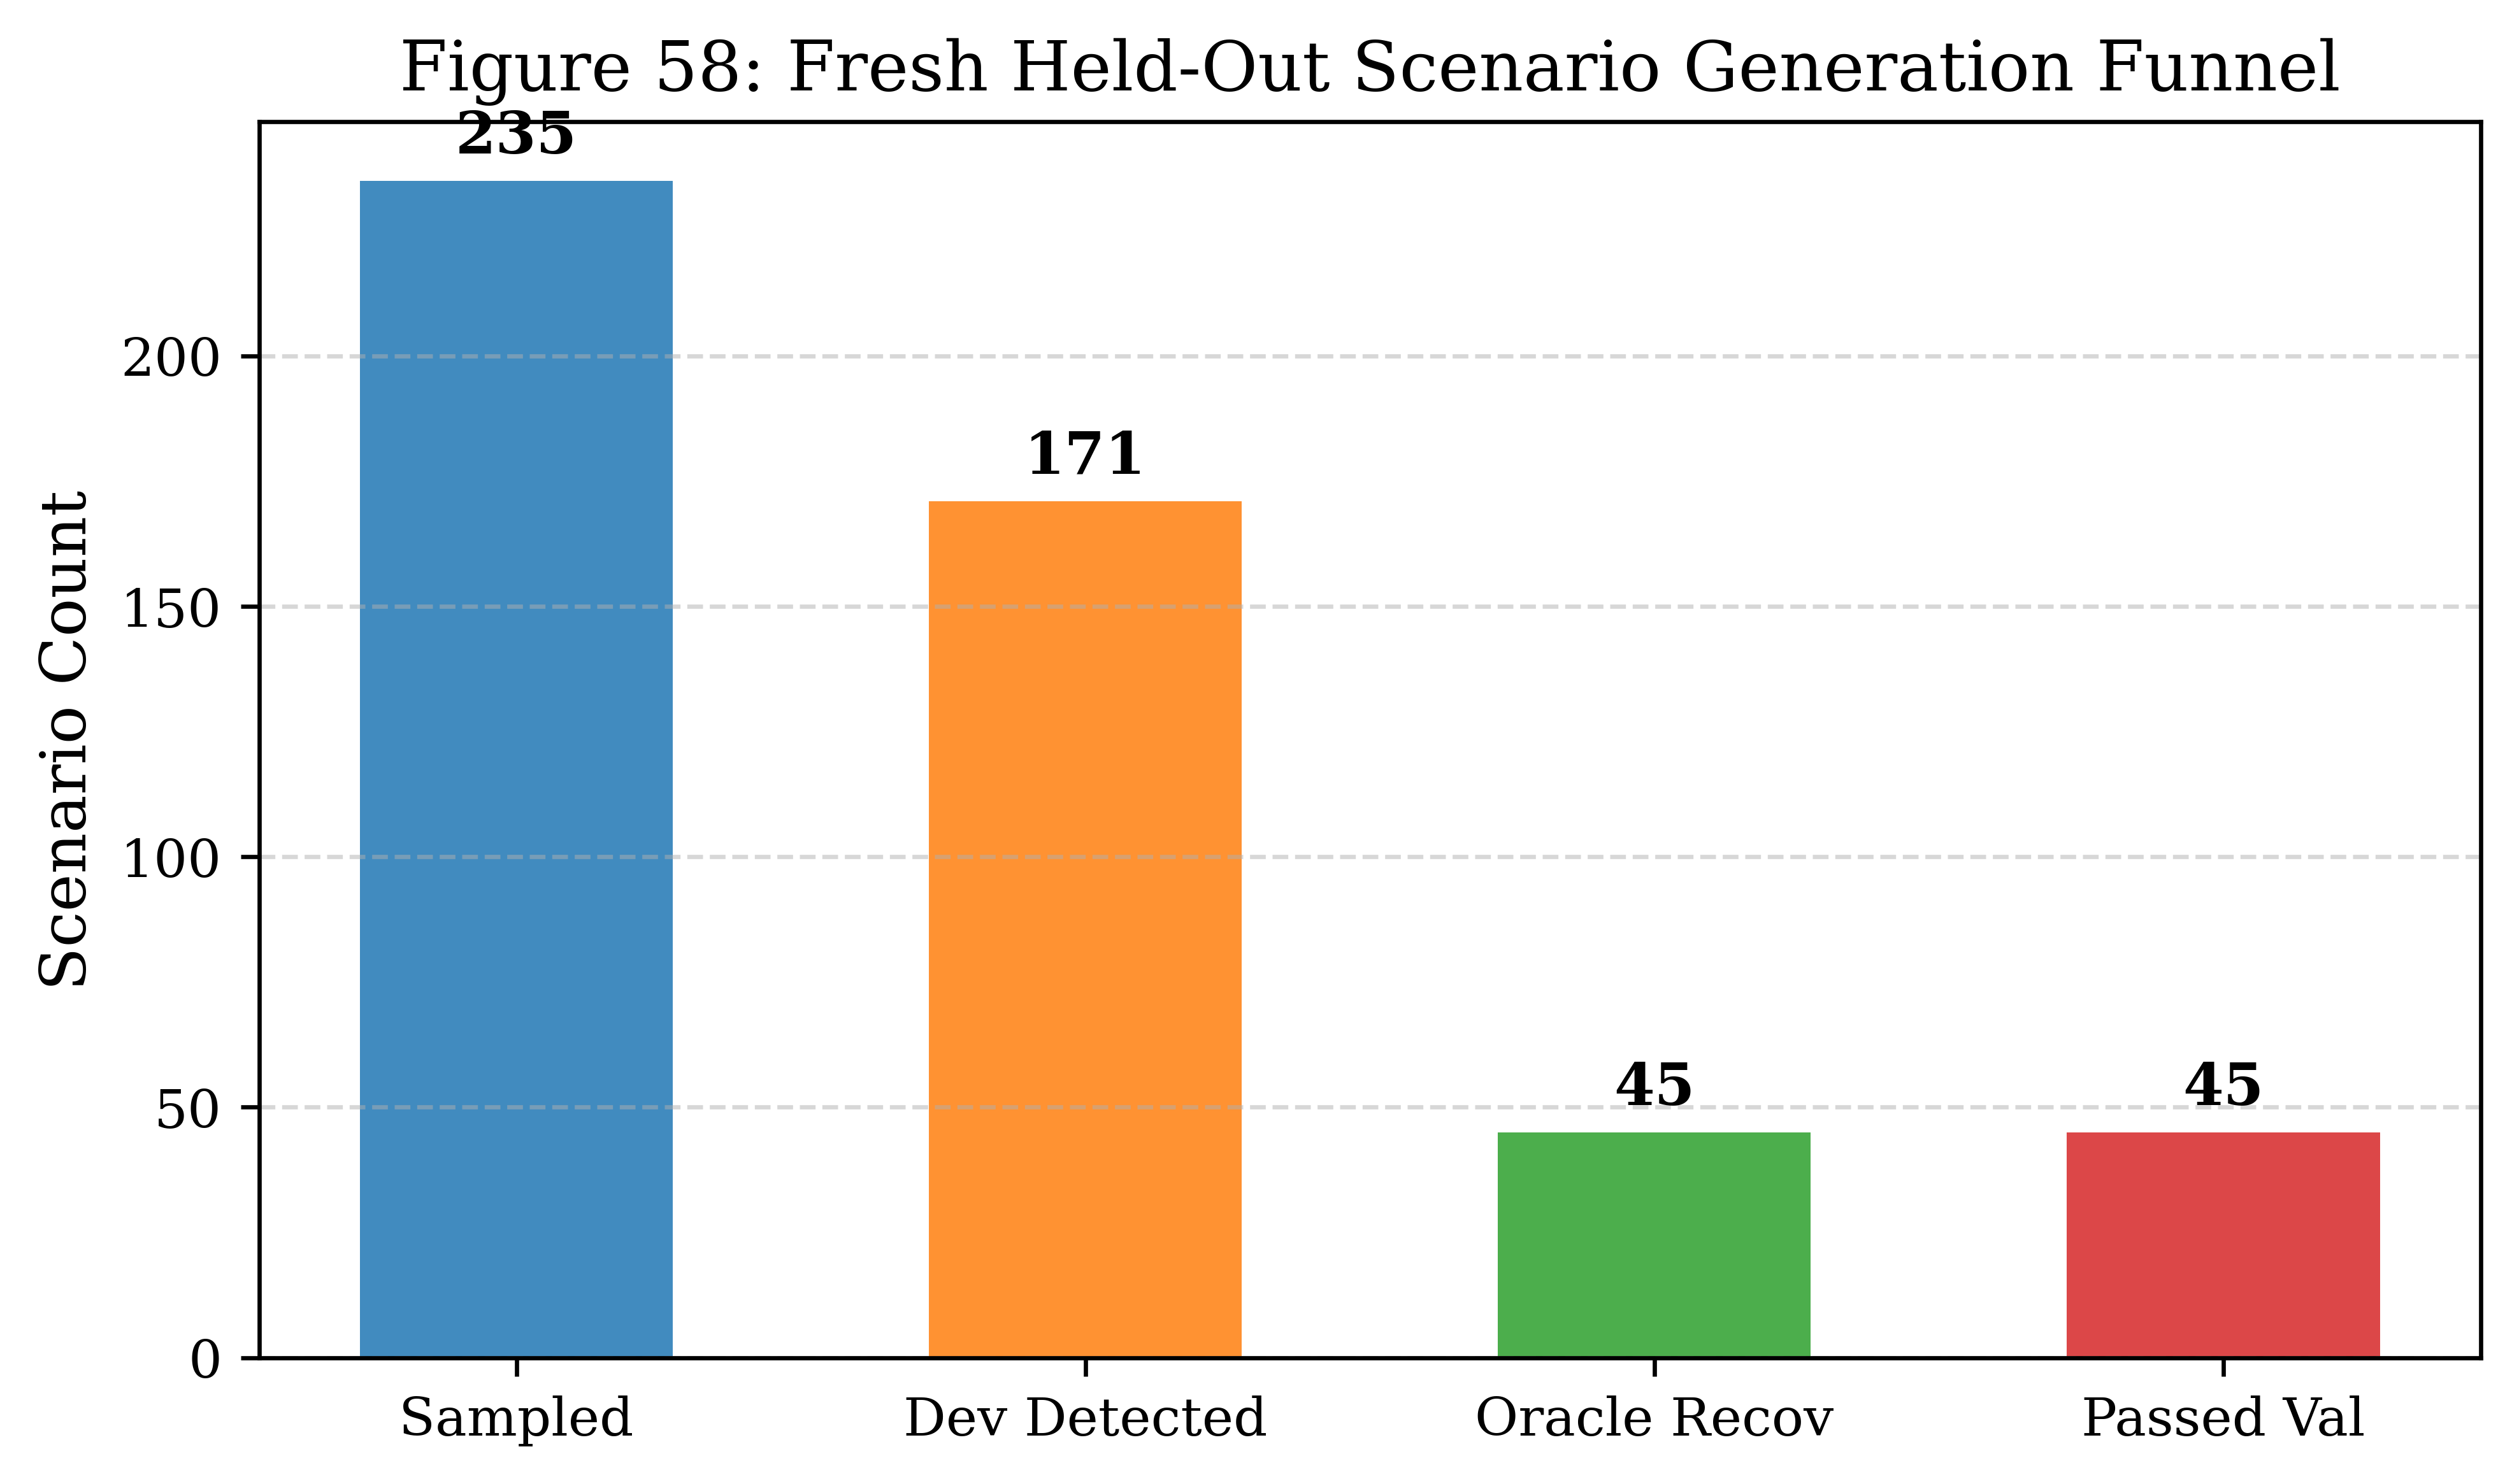

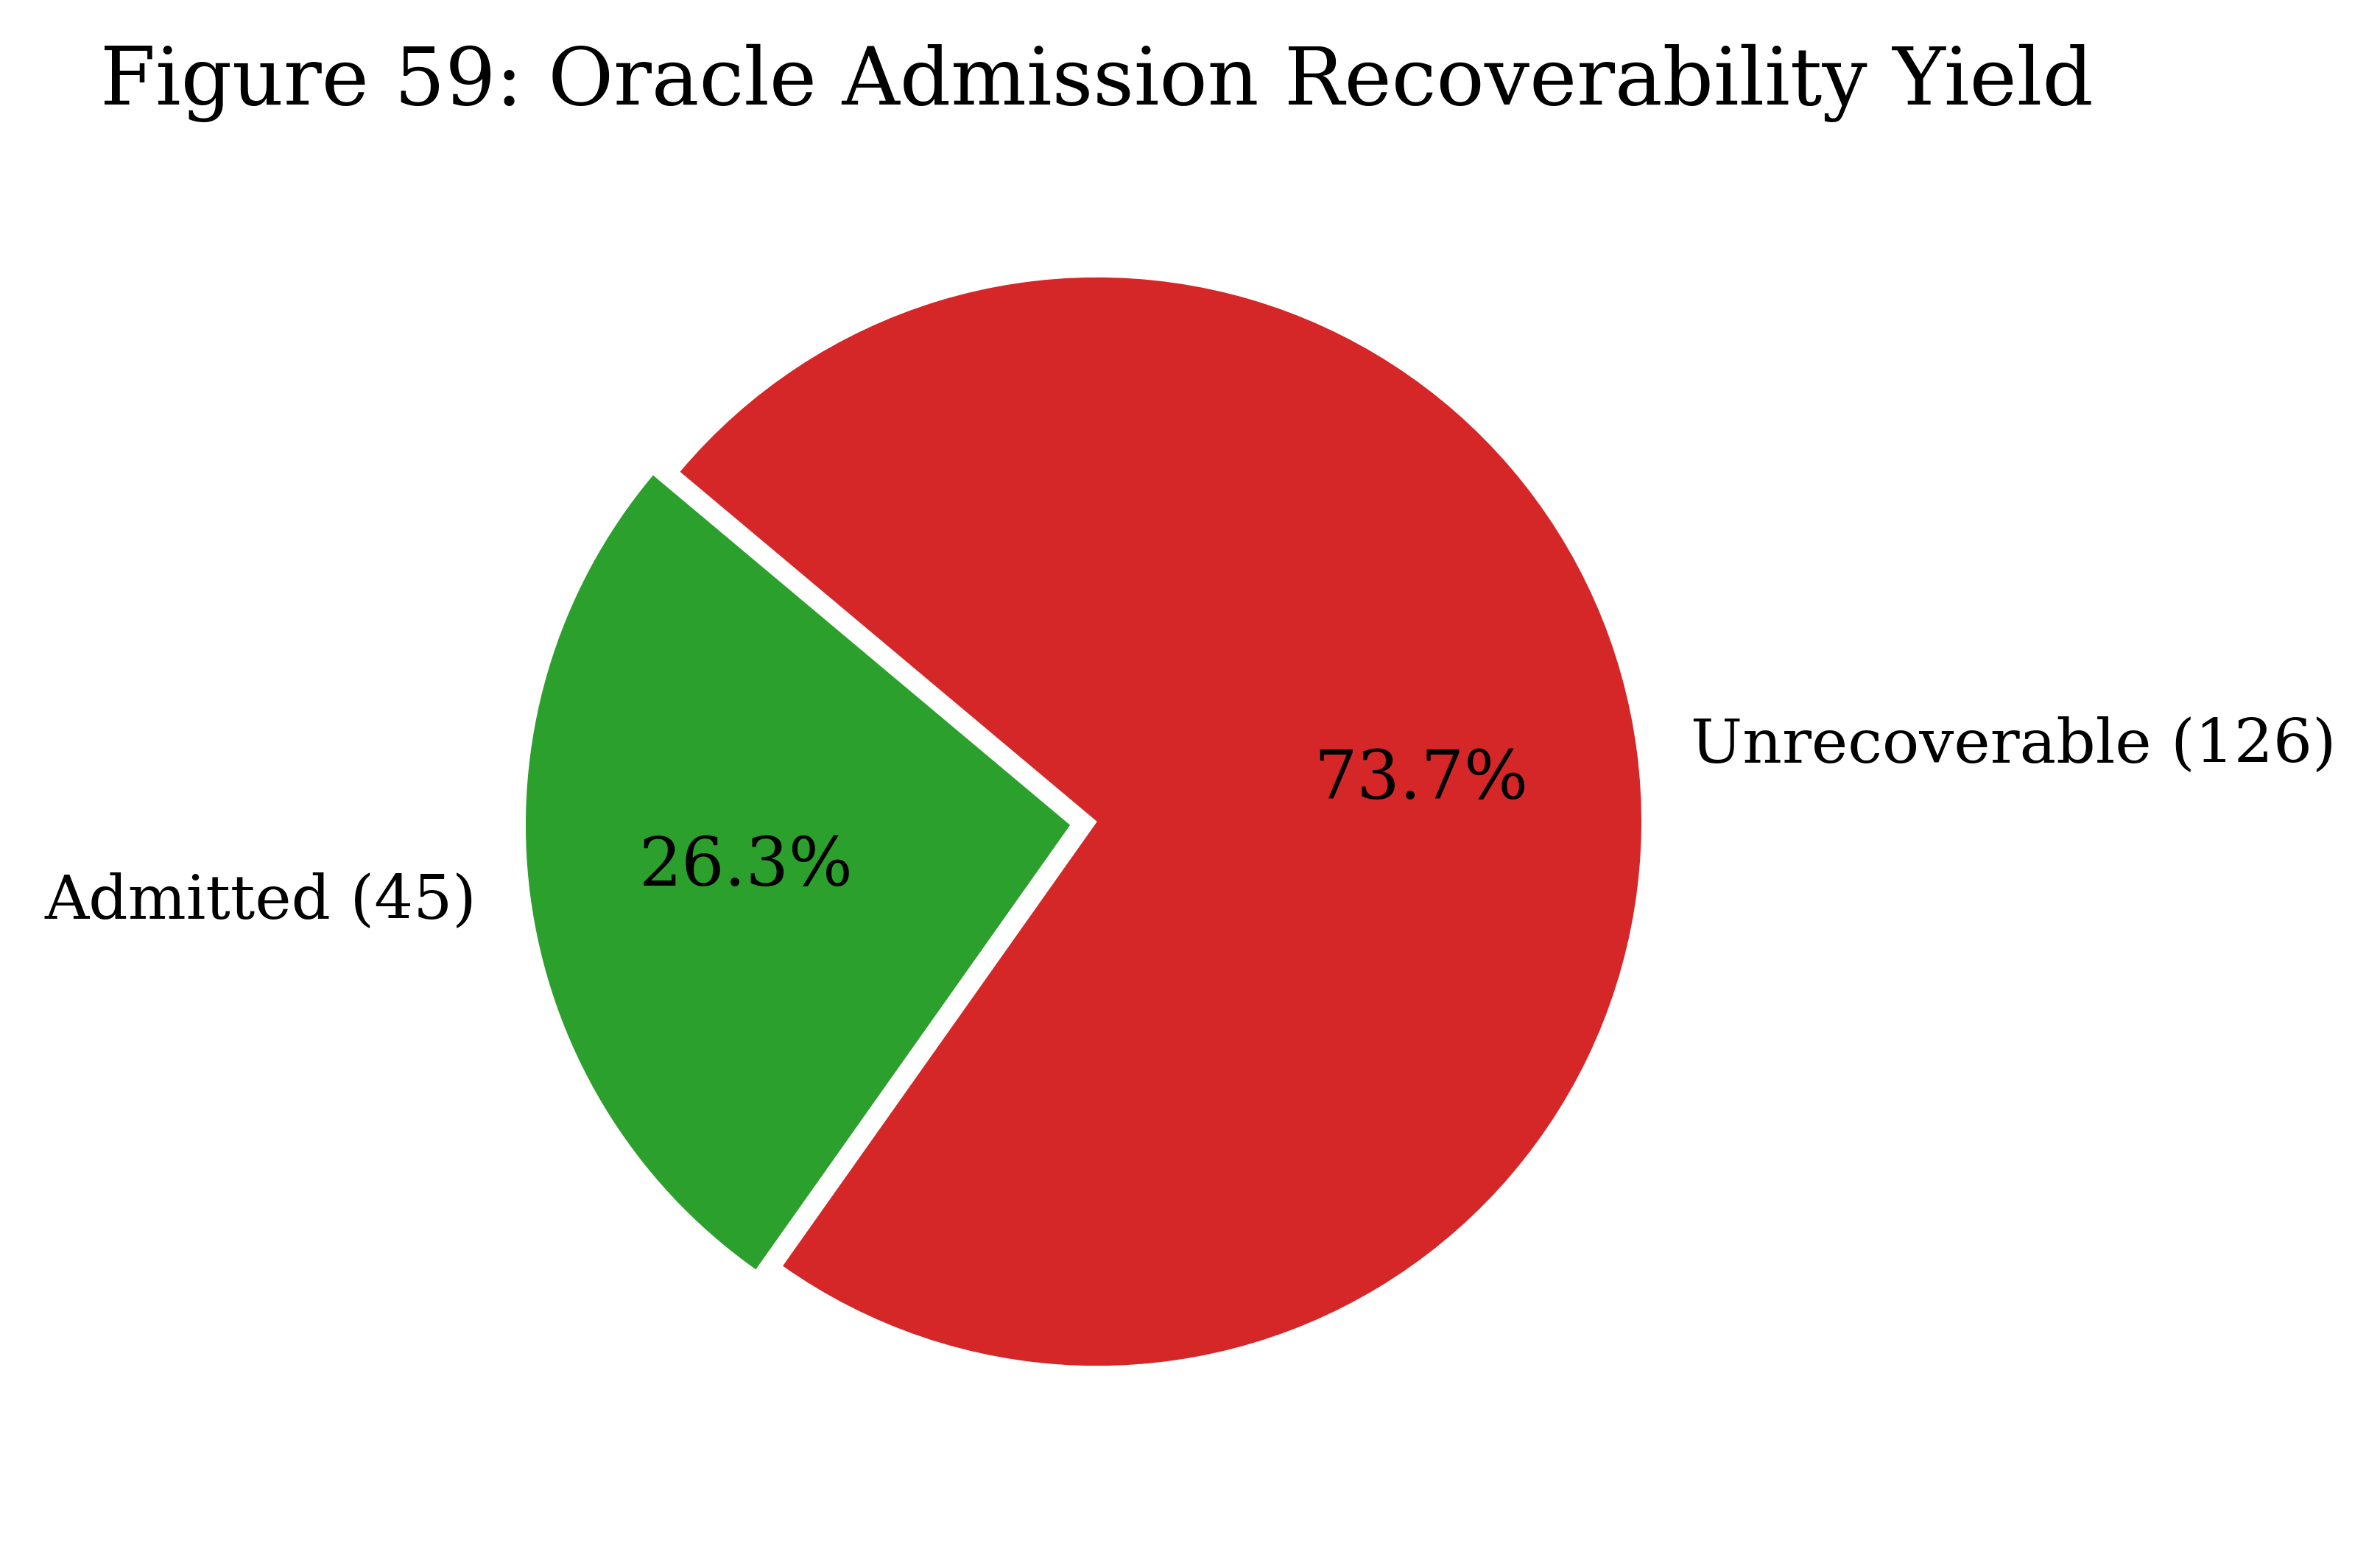

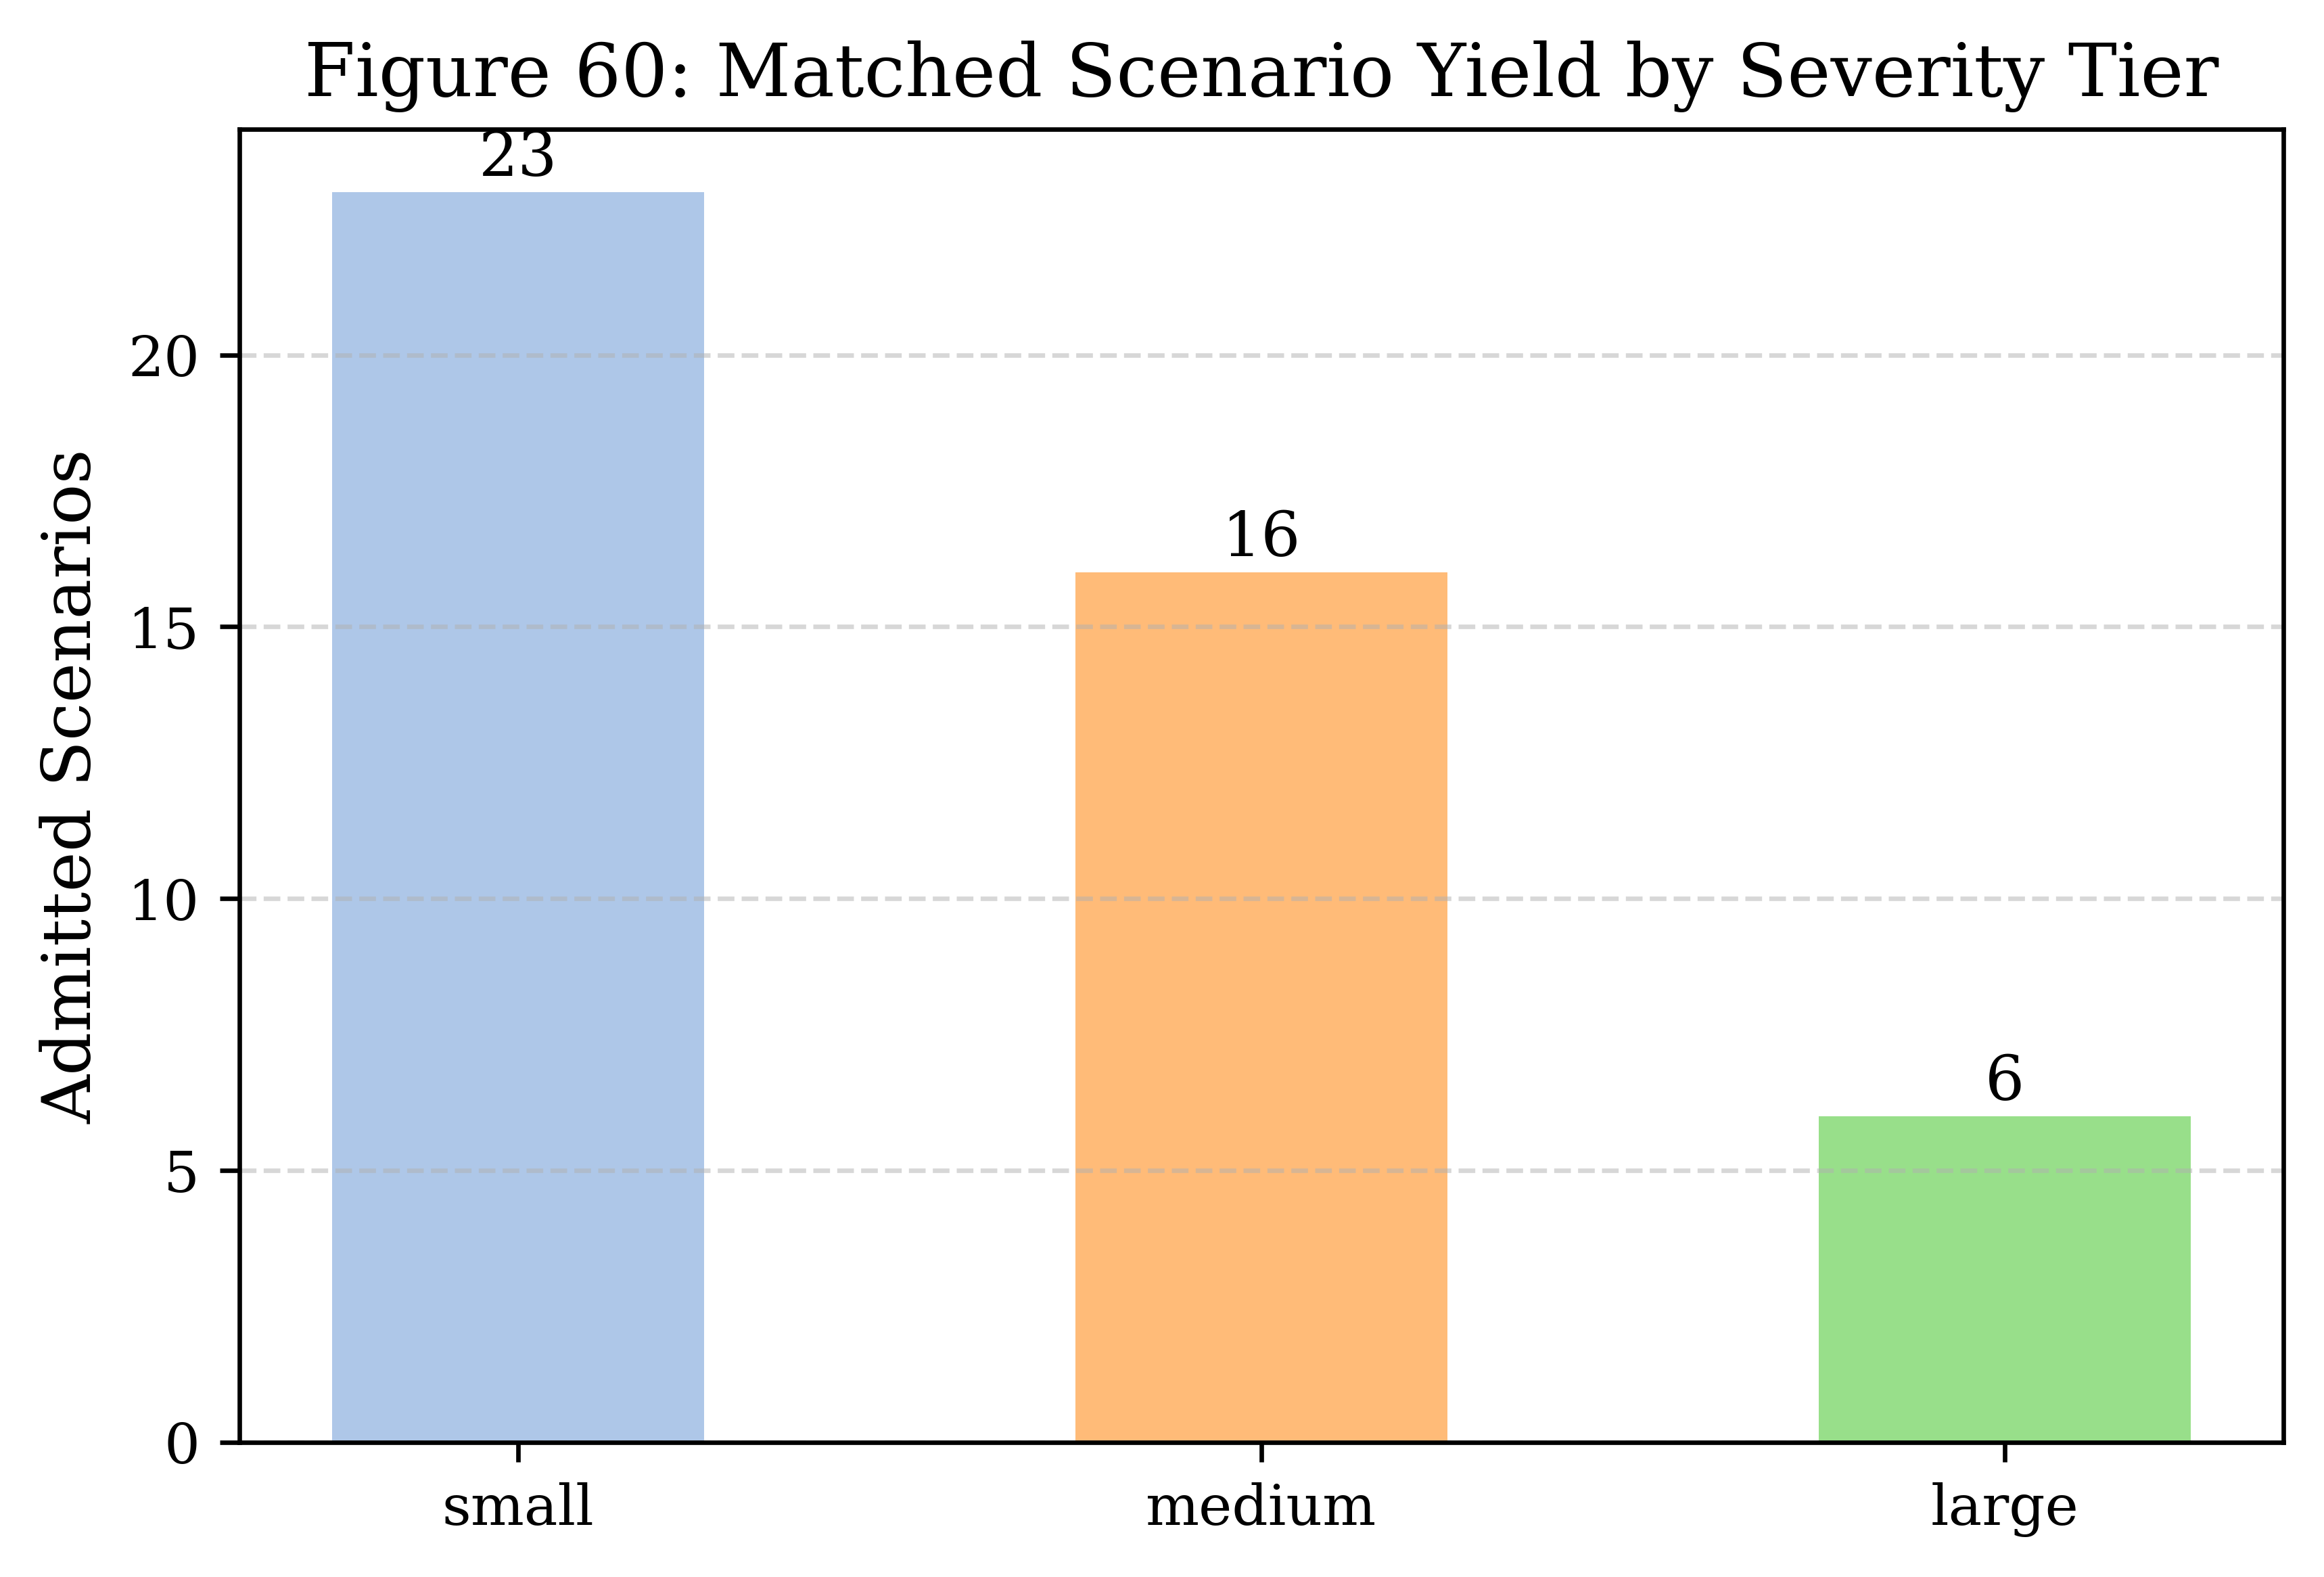

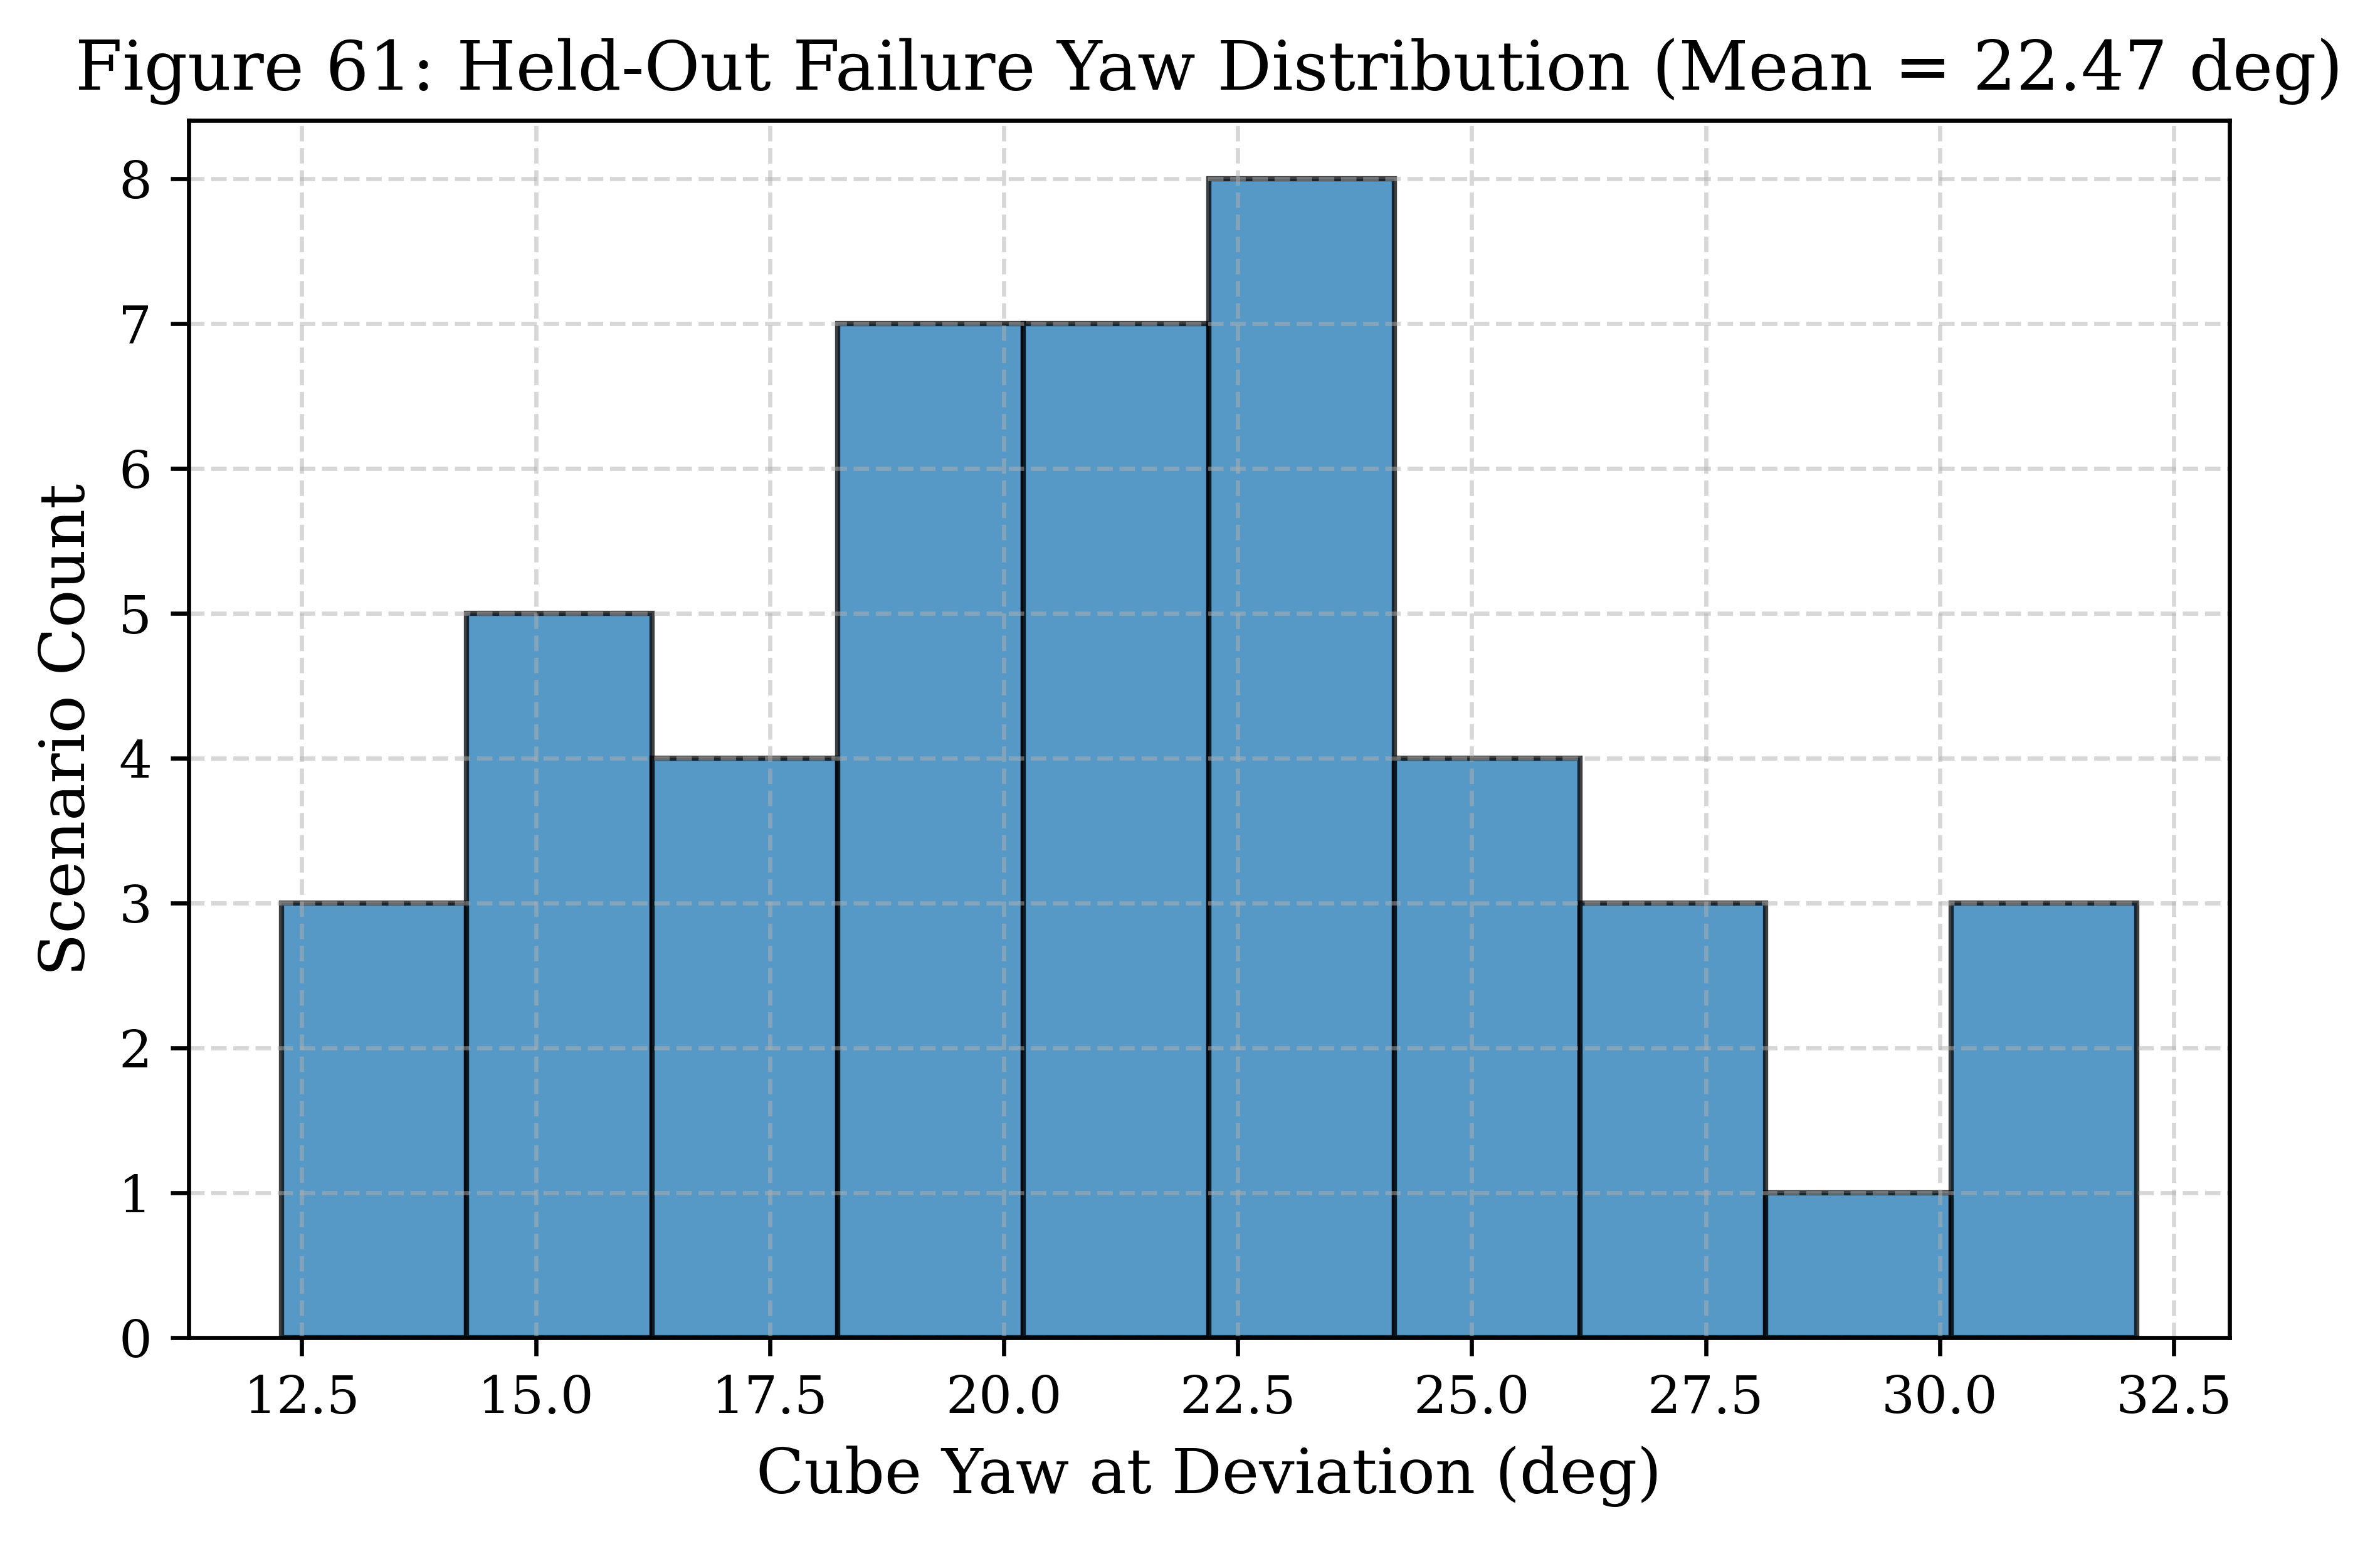

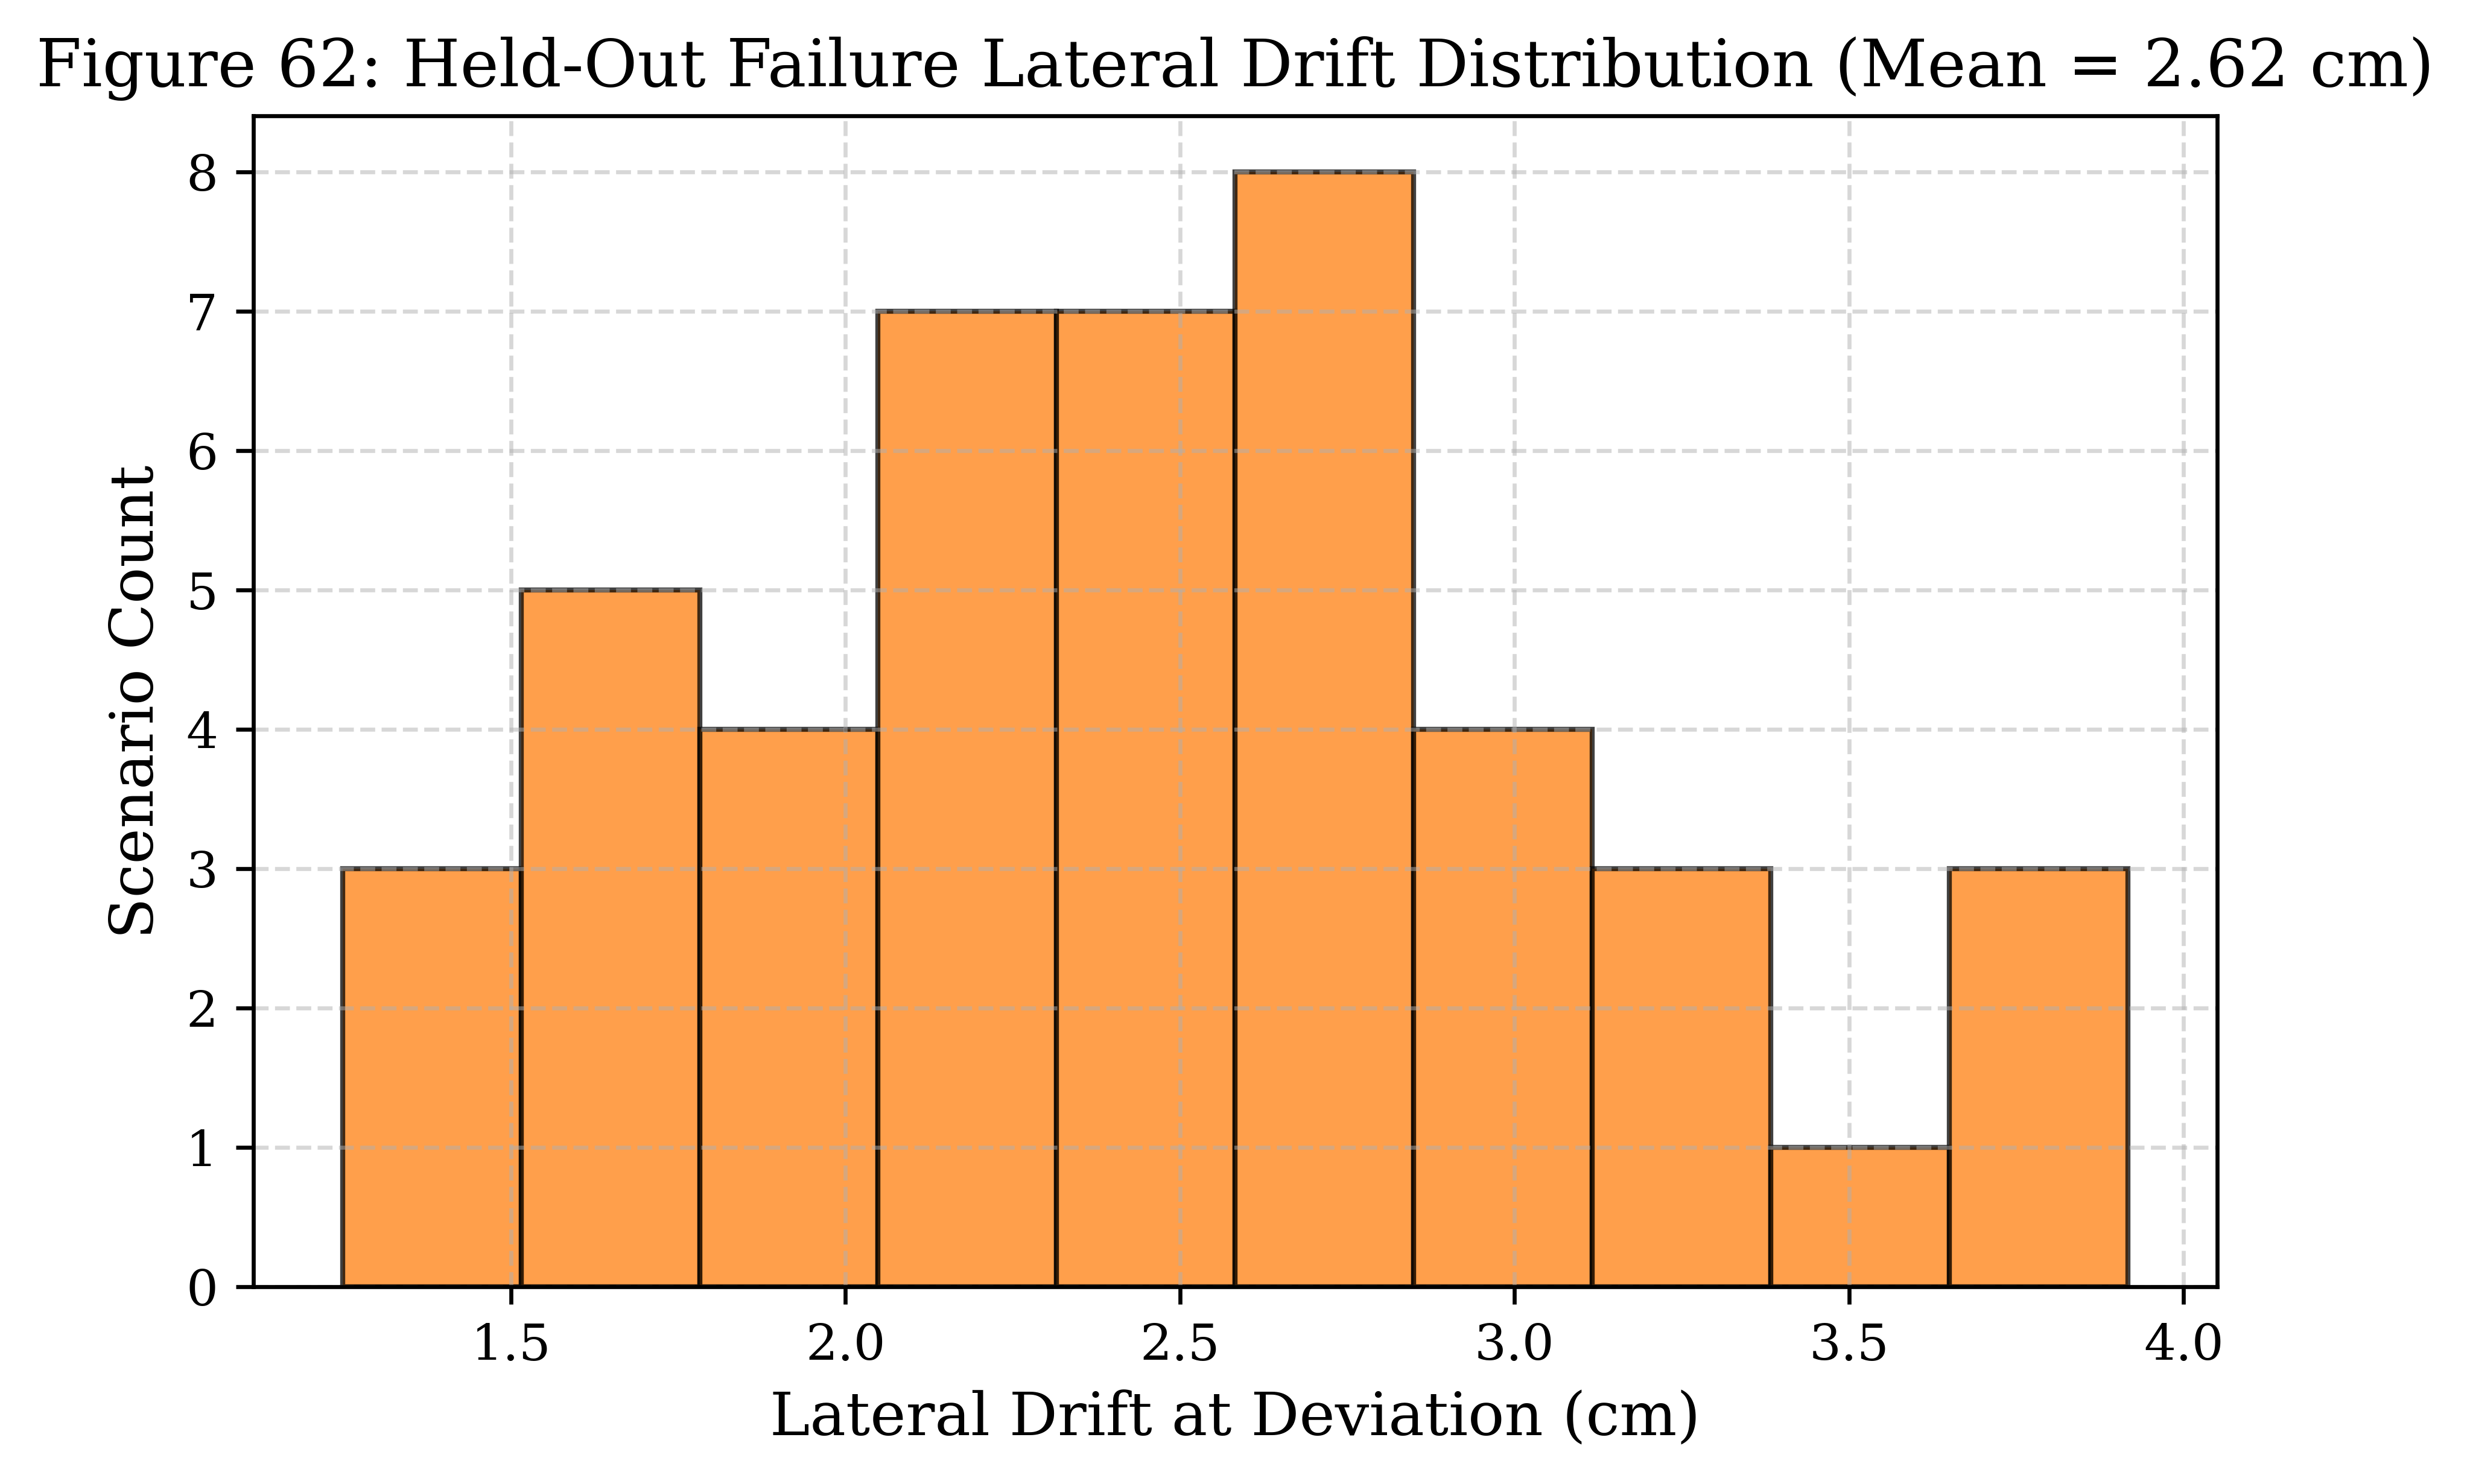

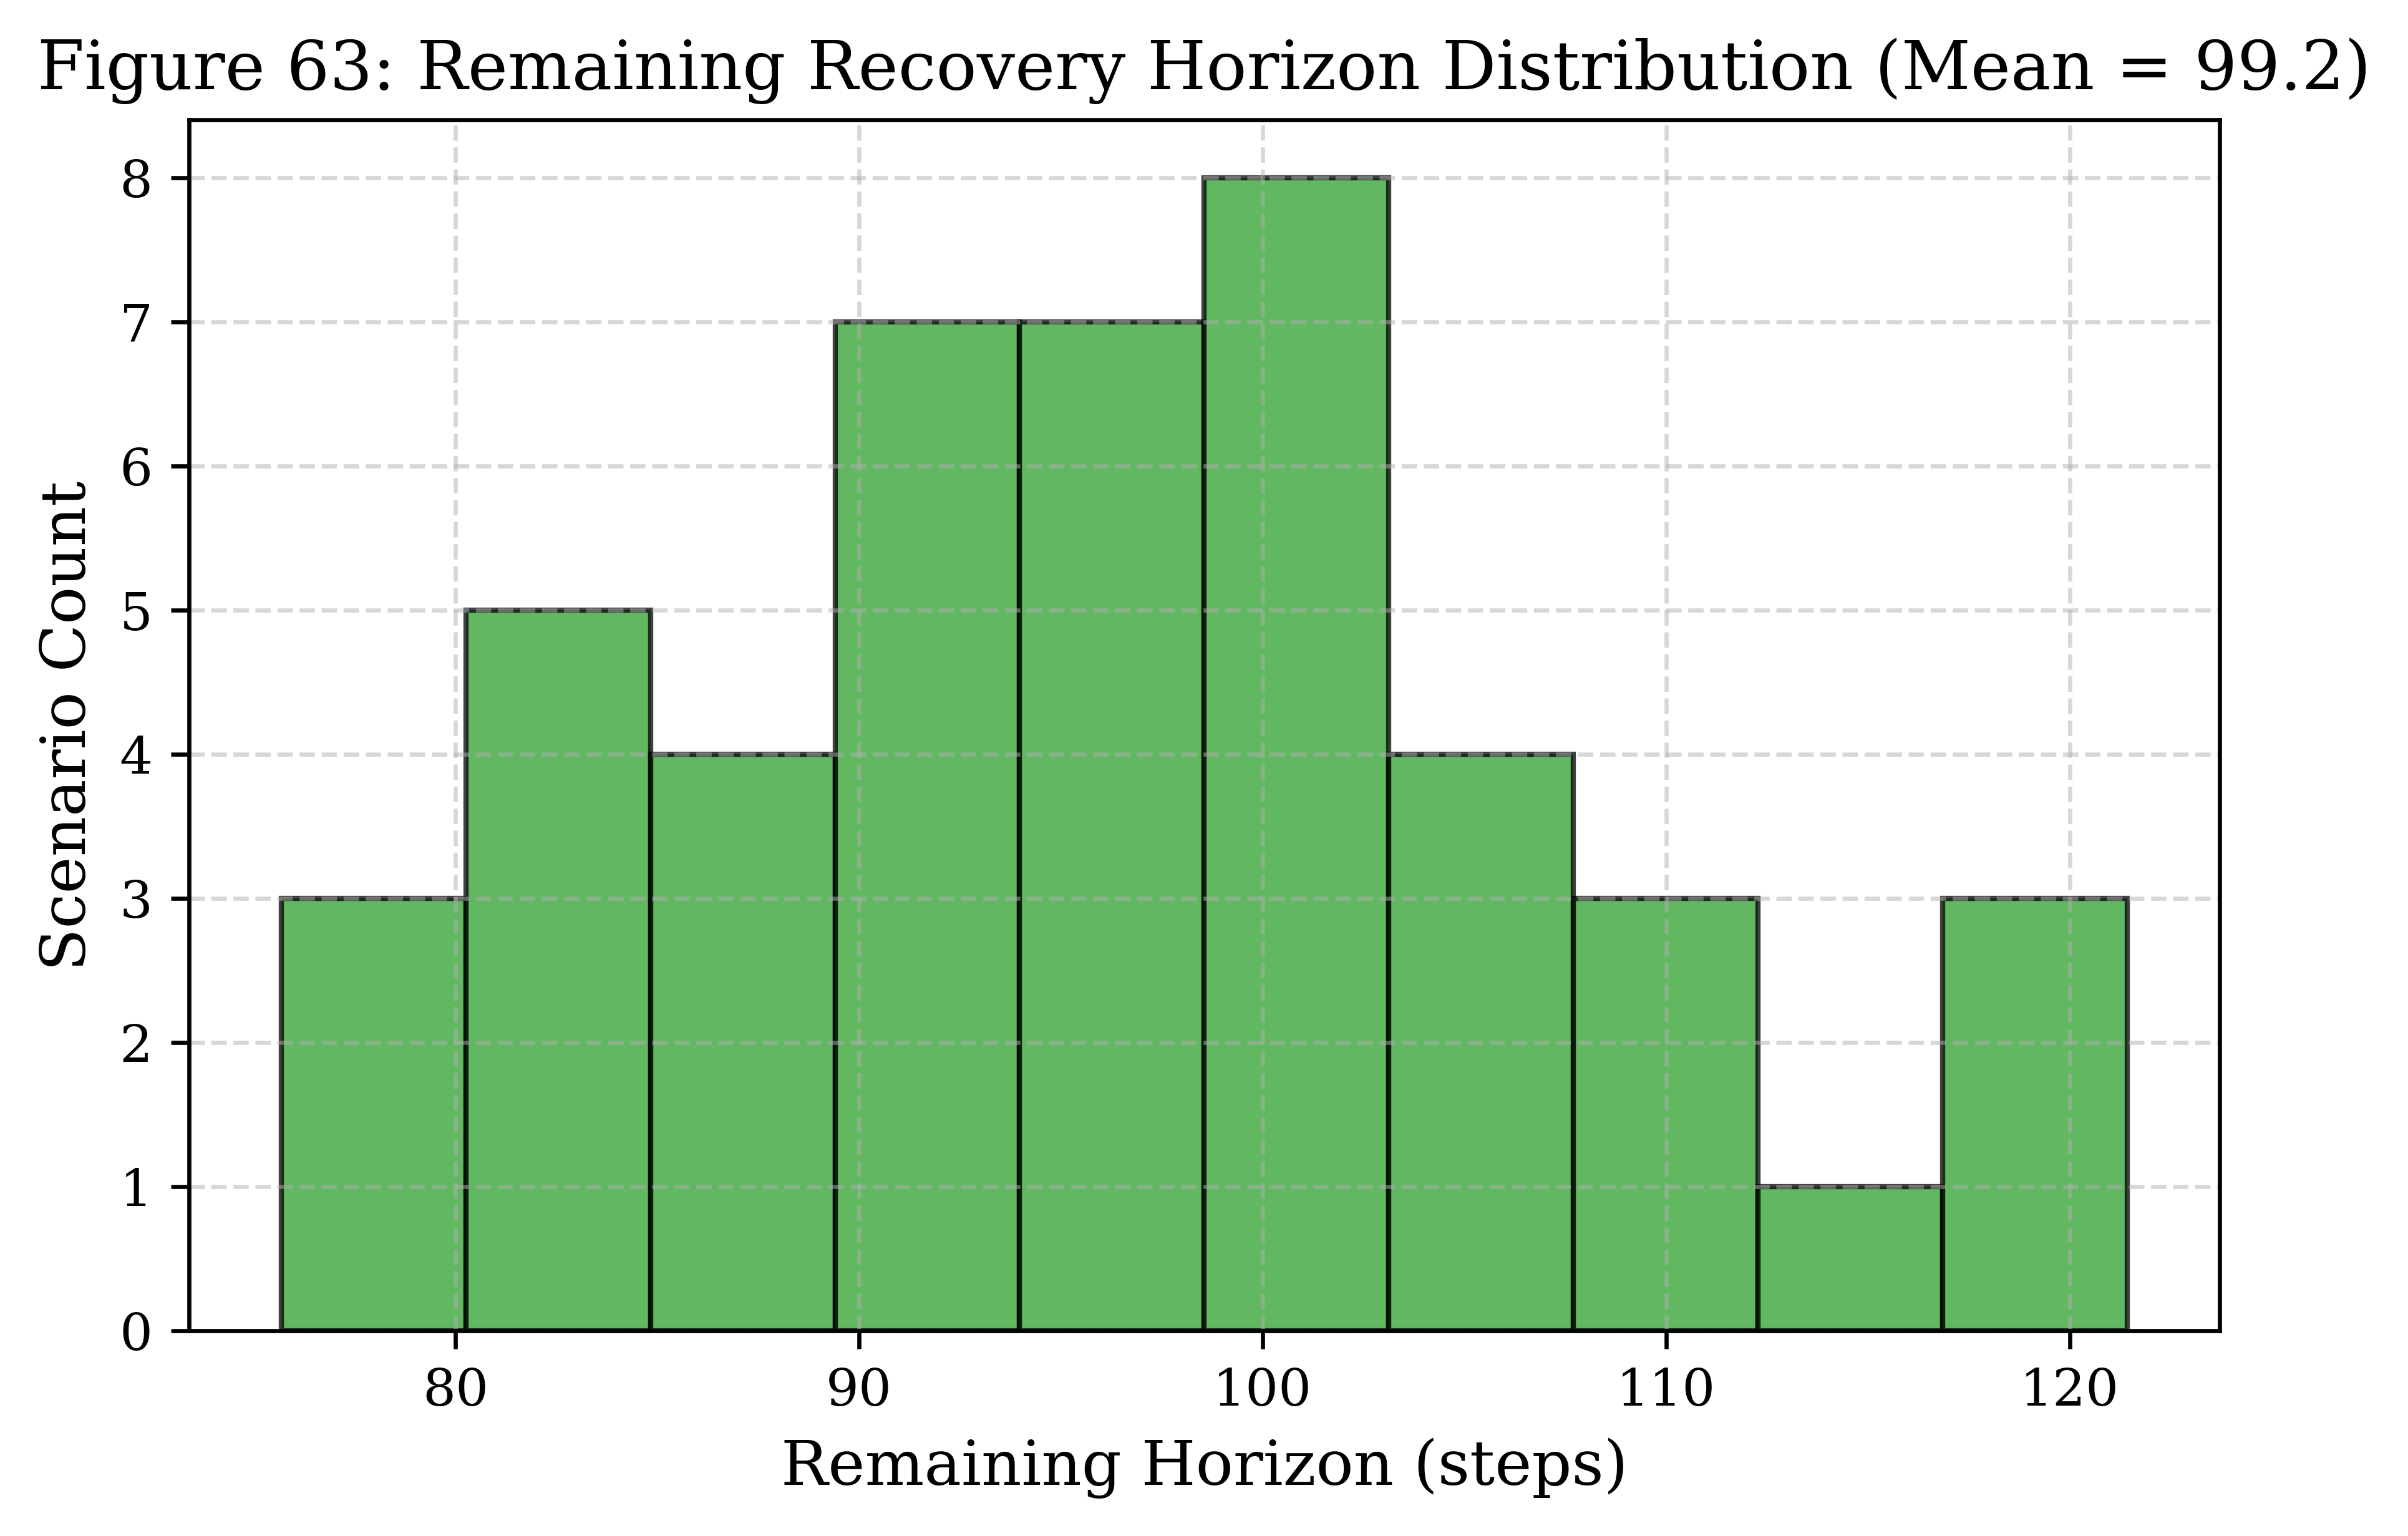

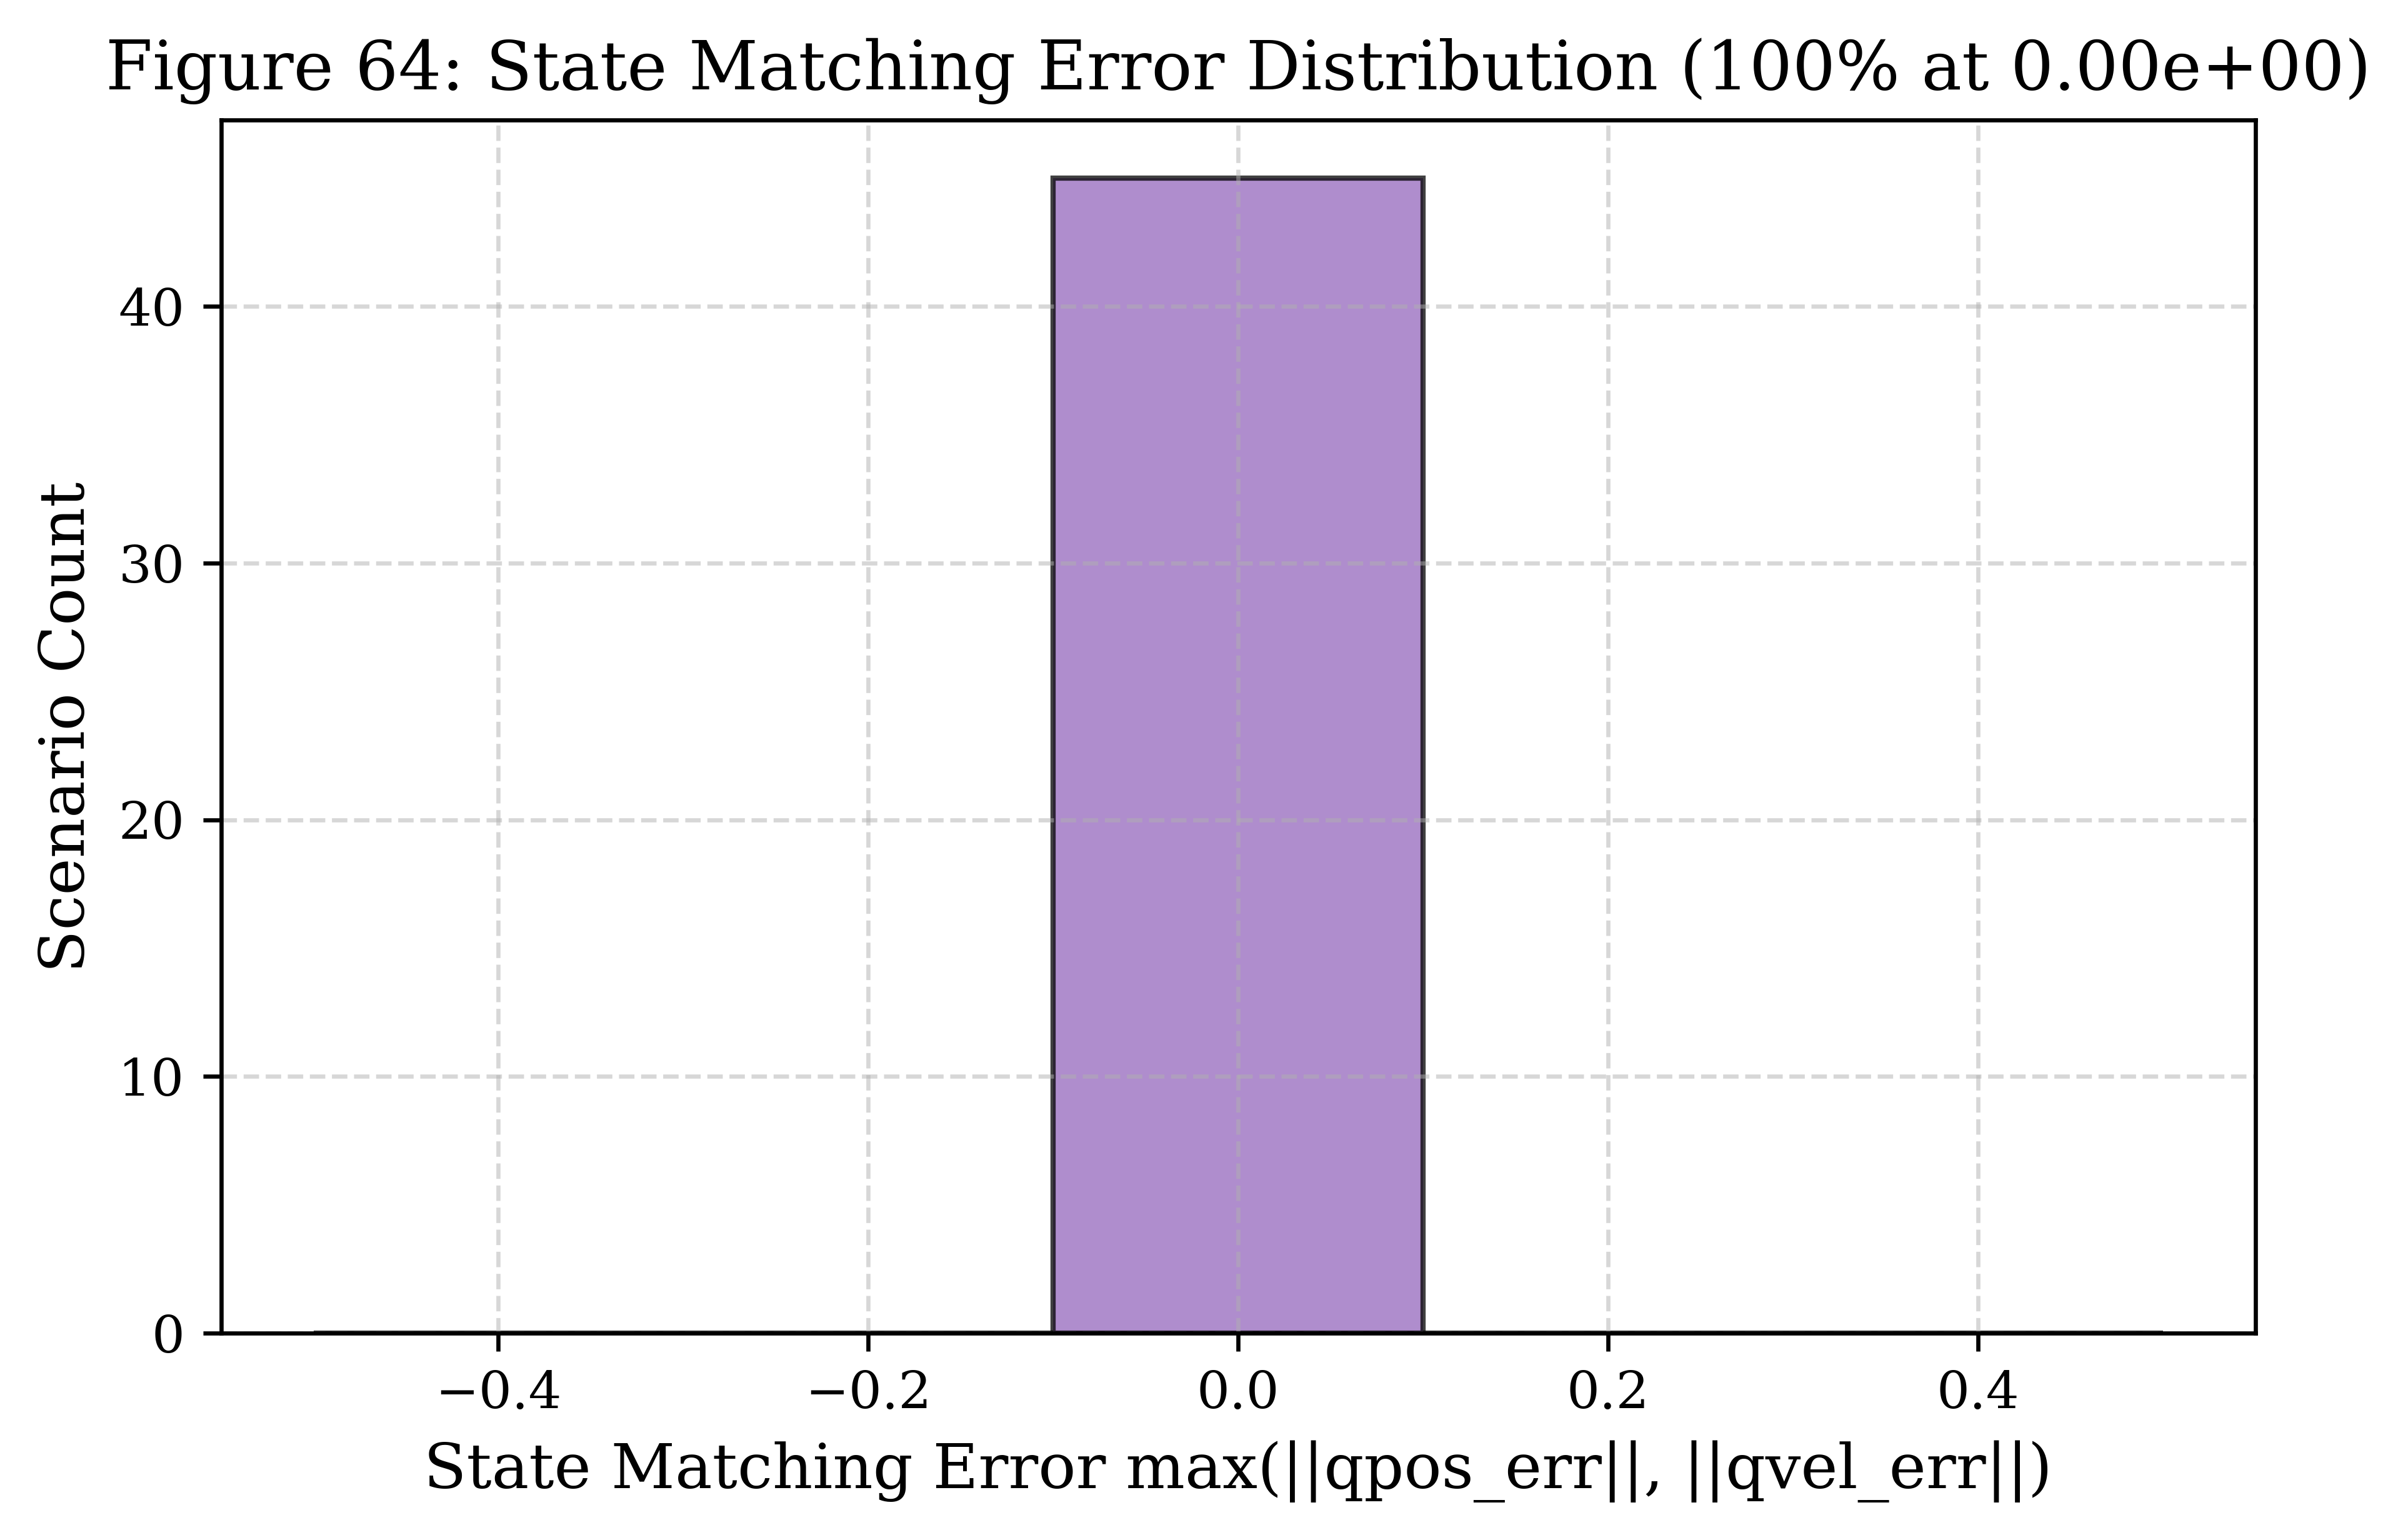

In [2]:
from IPython.display import Image, display
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig58_heldout_scenario_funnel.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig59_oracle_admission_yield.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig60_matched_scenario_yield.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig61_failure_yaw_distribution.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig62_lateral_drift_distribution.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig63_remaining_horizon_distribution.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig64_state_matching_error_distribution.png")))
